In [ ]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

**IMPORTANT NOTE:** This notebook is designed to run as a Colab. Click the button on top that says, `Open in Colab`, to run this notebook as a Colab. Running the notebook on your local machine might result in some of the code blocks throwing errors.

In [1]:
import csv
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from google.colab import files

In [2]:
# sign_mnist_train.csv
!gdown --id 1z0DkA9BytlLxO1C0BAWzknLyQmZAp0HR
# sign_mnist_test.csv
!gdown --id 1z1BIj4qmri59GWBG4ivMNFtpZ4AXIbzg

def get_data(filename):
  # You will need to write code that will read the file passed
  # into this function. The first line contains the column headers
  # so you should ignore it
  # Each successive line contians 785 comma separated values between 0 and 255
  # The first value is the label
  # The rest are the pixel values for that picture
  # The function will return 2 np.array types. One with all the labels
  # One with all the images
  #
  # Tips: 
  # If you read a full line (as 'row') then row[0] has the label
  # and row[1:785] has the 784 pixel values
  # Take a look at np.array_split to turn the 784 pixels into 28x28
  # You are reading in strings, but need the values to be floats
  # Check out np.array().astype for a conversion
    with open(filename) as training_file:
        # Your code starts here
        lines = training_file.readlines()
        images = [np.array_split(line.split(',')[1:], 28) for line in lines[1:]]
        labels = [line.split(',')[0] for line in lines[1:]]
        images = np.array(images).astype('float')
        labels = np.array(labels).astype('float')
        # Your code ends here
    return images, labels

training_images, training_labels = get_data('./sign_mnist_train.csv')
testing_images, testing_labels = get_data('./sign_mnist_test.csv')

# Keep these
print(training_images.shape)
print(training_labels.shape)
print(testing_images.shape)
print(testing_labels.shape)

# Their output should be:
# (27455, 28, 28)
# (27455,)
# (7172, 28, 28)
# (7172,)

Downloading...
From: https://drive.google.com/uc?id=1z0DkA9BytlLxO1C0BAWzknLyQmZAp0HR
To: /content/sign_mnist_train.csv
100% 83.3M/83.3M [00:00<00:00, 109MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1z1BIj4qmri59GWBG4ivMNFtpZ4AXIbzg
To: /content/sign_mnist_test.csv
100% 21.8M/21.8M [00:00<00:00, 59.7MB/s]
(27455, 28, 28)
(27455,)
(7172, 28, 28)
(7172,)


In [3]:
# In this section you will have to add another dimension to the data
# So, for example, if your array is (10000, 28, 28)
# You will need to make it (10000, 28, 28, 1)
# Hint: np.expand_dims

training_images = np.expand_dims(training_images, axis=3) ### YOUR CODE HERE
testing_images = np.expand_dims(testing_images, axis=3) ### YOUR CODE HERE

train_datagen = ImageDataGenerator(
    ### YOUR CODE HERE
    rescale=1/255.,
    rotation_range=40,
    height_shift_range=0.2,
    width_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=False,
    fill_mode='nearest'
    )

validation_datagen = ImageDataGenerator(
    ### YOUR CODE HERE
    rescale=1/255.
    )

train_data = train_datagen.flow(training_images, training_labels, batch_size=256)
test_data = validation_datagen.flow(testing_images, testing_labels, batch_size=256)

# Keep These
print(training_images.shape)
print(testing_images.shape)
    
# Their output should be:
# (27455, 28, 28, 1)
# (7172, 28, 28, 1)

(27455, 28, 28, 1)
(7172, 28, 28, 1)


In [5]:
# Define the model
# Use no more than 2 Conv2D and 2 MaxPooling2D
model = tf.keras.models.Sequential([
    ### START CODE HERE                                
    tf.keras.layers.Conv2D(16, (3,3), activation='relu', input_shape=(28,28,1)),
    tf.keras.layers.MaxPool2D((2,2)),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPool2D((2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(25, activation='softmax')
    ### END CODE HERE
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop', metrics=['accuracy']) ### YOUR CODE HERE

history = model.fit(
    train_data,
    epochs=20,
    validation_data=test_data
) ### YOUR CODE HERE

model.evaluate(testing_images, testing_labels)

# The output from model.evaluate should be close to:
# [6.92426086682151, 0.56609035]


Epoch 1/20
108/108 [==============================] - 40s 97ms/step - loss: 3.0399 - accuracy: 0.1031 - val_loss: 2.7012 - val_accuracy: 0.1832
Epoch 2/20
108/108 [==============================] - 10s 96ms/step - loss: 2.7454 - accuracy: 0.1893 - val_loss: 2.2869 - val_accuracy: 0.3305
Epoch 3/20
108/108 [==============================] - 10s 94ms/step - loss: 2.5237 - accuracy: 0.2543 - val_loss: 1.8440 - val_accuracy: 0.5226
Epoch 4/20
108/108 [==============================] - 10s 96ms/step - loss: 2.3342 - accuracy: 0.3048 - val_loss: 1.6257 - val_accuracy: 0.5488
Epoch 5/20
108/108 [==============================] - 10s 97ms/step - loss: 2.1612 - accuracy: 0.3518 - val_loss: 1.6126 - val_accuracy: 0.5074
Epoch 6/20
108/108 [==============================] - 10s 96ms/step - loss: 2.0090 - accuracy: 0.3917 - val_loss: 1.2369 - val_accuracy: 0.6354
Epoch 7/20
108/108 [==============================] - 10s 95ms/step - loss: 1.8684 - accuracy: 0.4305 - val_loss: 1.3158 - val_accuracy:

[101.84716796875, 0.6542108058929443]

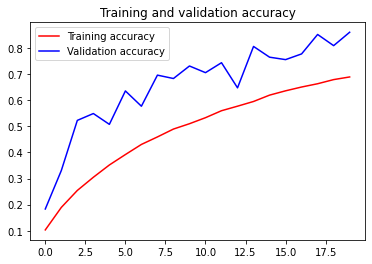

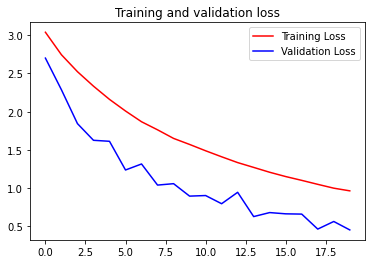

In [6]:
# Plot the chart for accuracy and loss on both training and validation

import matplotlib.pyplot as plt
acc = history.history['accuracy'] ### YOUR CODE HERE
val_acc = history.history['val_accuracy'] ### YOUR CODE HERE
loss = history.history['loss'] ### YOUR CODE HERE
val_loss = history.history['val_loss'] ### YOUR CODE HERE

epochs = range(len(acc))

plt.plot(epochs, acc, 'r', label='Training accuracy')
plt.plot(epochs, val_acc, 'b', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()

plt.plot(epochs, loss, 'r', label='Training Loss')
plt.plot(epochs, val_loss, 'b', label='Validation Loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()